# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

In [3]:
# 1.1 Завантаження датасету
df = pd.read_csv('drive/MyDrive/Data Loves/Модуль 16. Основи машинного навчання/House_Rent_Dataset.csv')

In [4]:
# 1.2 Виведення розміру датасету
df.shape
print(f'Набір містить {df.shape[0]} рядків та {df.shape[1]} колонок.')

Набір містить 4746 рядків та 12 колонок.


In [5]:
# 1.3 Виведення перших 5 рядків датасету
df.head(5)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [6]:
# 1.4 Виведення загальної інформації про дані (включно з типами даних та кількістю значень)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [7]:
# 2.1 Аналіз пропущених значень
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100

missing_percent

,0
Posted On,0.0
BHK,0.0
Rent,0.0
Size,0.0
Floor,0.0
Area Type,0.0
Area Locality,0.0
City,0.0
Furnishing Status,0.0
Tenant Preferred,0.0


Відсутніх значень в колонках немає.

In [8]:
# 2.2 Базова статистика
stats = df[['BHK', 'Rent', 'Size', 'Bathroom']].describe()
stats.round(2)

,BHK,Rent,Size,Bathroom
count,4746.00,4746.00,4746.00,4746.00
mean,2.08,34993.45,967.49,1.97
std,0.83,78106.41,634.20,0.88
min,1.00,1200.00,10.00,1.00
25%,2.00,10000.00,550.00,1.00
50%,2.00,16000.00,850.00,2.00
75%,3.00,33000.00,1200.00,2.00
max,6.00,3500000.00,8000.00,10.00


Висновок з базової статистики:
 - Rent має сильно скошений розподіл і викиди, тому що середнє значення майже в два рази більше за медіану. Також майже в 100 разів максимальне значення перевищує 75 персентиль та стандартне відхилення значно перевищує середнє значення.
- Size містить підозрілі значення через наявність 8000 квадратних футів при медіані 850 та 75 персентилі 1200. Також дивно виглядає мінімальне значення 10 квадратних футів, на якій наявна 1 ванна кімната та кімната, що викликає підозру в коректності таких записів.
- BHK і Bathroom має досить типовий вид житла. Кількість кімнат від 1 до 6. Ванних кімнат зазвичай 1-2, але максимум 10 при максимумі 6 спалень виглядає незвично. Варто перевірити ці рядки.



In [9]:
# 2.3 Аналіз цільової змінної через побудову гістограми
fig = px.histogram(
    df,
    x='Rent',
    nbins=100,
    title='Розподіл цільової змінної (вартість оренди)',
    labels={'Rent': 'Вартість оренди'}
)
fig.update_layout(
    showlegend=False,
    height=400,
    yaxis_title='Кількість значень'
)
fig.show()

In [10]:
# 2.4 Робота з викидами. Метод IQR (міжквартильного розмаху)

# Межі за методом IQR для Rent
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Новий датафрейм без викидів
df_clean = df[(df['Rent'] >= lower_bound) & (df['Rent'] <= upper_bound)].copy()

print(f"Було рядків: {len(df)}")
print(f"Стало рядків: {len(df_clean)}")
print(f"Видалено викидів: {len(df) - len(df_clean)}")

Було рядків: 4746
Стало рядків: 4226
Видалено викидів: 520


In [11]:
# 2.5 Аналіз категоріальних змінних

# Вибираємо категоріальні колонки
category_cols = df.select_dtypes(include=['object', 'category']).columns

# Кількість унікальних значень у кожній категоріальній колонці
df[category_cols].nunique()

,0
Posted On,81
Floor,480
Area Type,3
Area Locality,2235
City,6
Furnishing Status,3
Tenant Preferred,3
Point of Contact,3



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


In [12]:
# 3.1 Створюємо датафрейм тільки з числовими метриками
correlation_matrix = df_clean.select_dtypes('number').corr()

# 3.2 Візуалізація кореляцій
fig = px.imshow(
    correlation_matrix,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    title='Кореляційна матриця всіх числових ознак',
    labels=dict(color="Кореляція")
)
fig.update_layout(height=500)
fig.show()

З графіку видно, що:
 - спостерігається сильна позитивна кореляція між Bathroom та BHK, що означає збільшення кількості ванних кімнат при збільшенні кількості кімнат в помешканні
- спостерігається сильна позитивна кореляція між BHK і Size, що є теж доволі логічним. Чим більше кімнат, тим більша спостерігається площа помешкання.
- також спостерігається позитивна помірна кореляція між Size та Bathroom, тобто більші за площею помешкання, як правило, мають більше ванних кімнат.
 - що кореляція Rent з іншими метриками має позитивну помірну кореляцію (від 0.39 до 0.51)

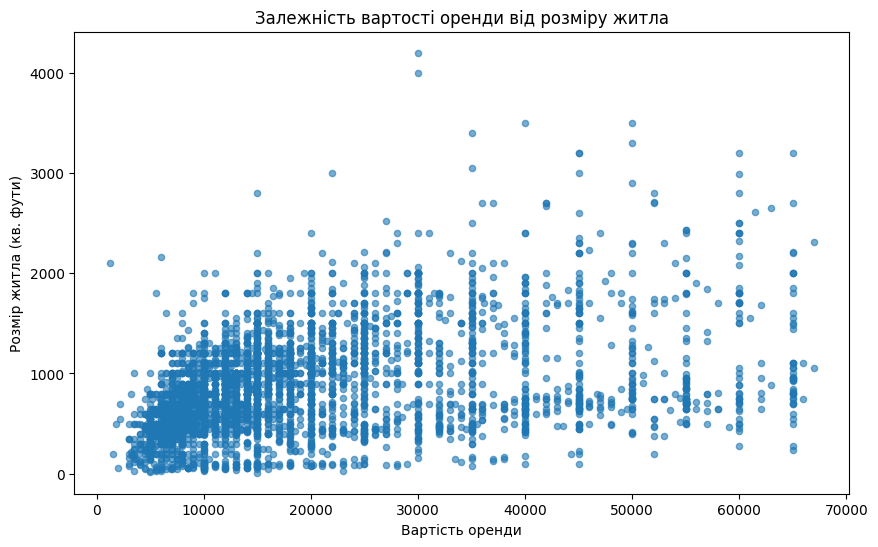

In [13]:
# 3.3 Побудова scatter plot між Size та Rent

df_clean.plot.scatter(
    x='Rent',
    y='Size',
    title='Залежність вартості оренди від розміру житла',
    figsize=(10, 6),
    alpha=0.6
)
plt.ylabel('Розмір житла (кв. фути)')
plt.xlabel('Вартість оренди')
plt.suptitle('')
plt.show()

З графіку можна побачити, що:
- основна маса даних зосереджена в нижньому лівому куті, де більшість об'єктів мають оренду до ~20 000 і площу до ~1500 кв. футів;
- є слабка-помірна позитивна залежність, але вона не жорстка, тому що спостерігається великий розкид даних, де при одній і тій самій оренді площа може кардинально відрізнятися. Наприклад, при 40 000-50 000 зустрічаються квартири по ~500 кв. футів, і по ~3000+. Тож вартість визначається не лише площею, а можуть впливати ще місто, район, меблювання, тип об'єкта тощо.
- зустрічаються нетипові точки: площа більше 2100 при оренді менше 2000 (дуже велике й надзвичайно дешеве житло), ймовірно помилка введення або нетипове оголошення.
Багато об'єктів з малою площею (до 200-300) мають високу оренду та навпаки.


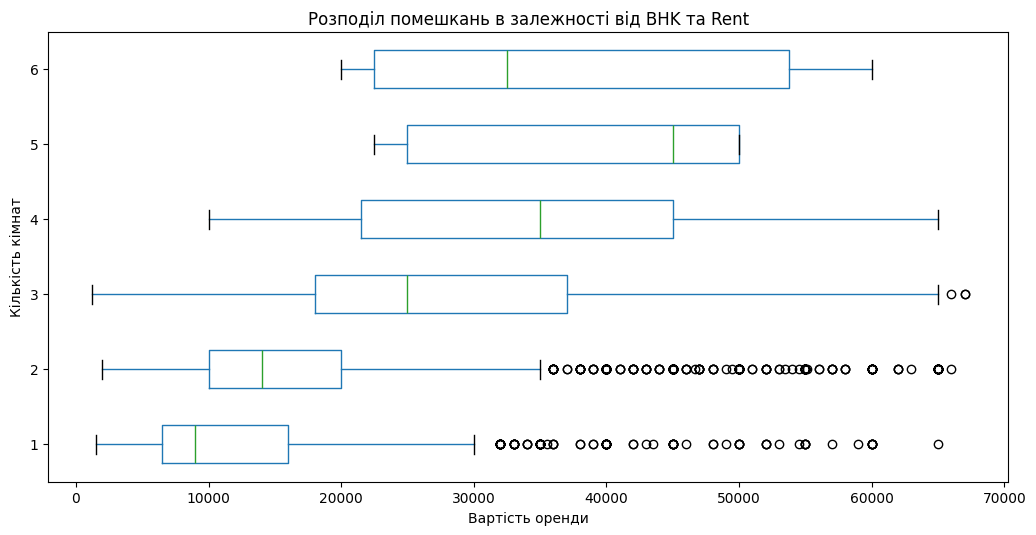

In [14]:
# 3.4 Аналіз взаємозв'язку між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)

df_clean.boxplot(
    column='Rent',
    by='BHK',
    figsize=(12, 6),
    grid = False,
    vert=False
)
plt.title('Розподіл помешкань в залежності від BHK та Rent')
plt.suptitle('')
plt.ylabel('Кількість кімнат')
plt.xlabel('Вартість оренди')
plt.show()

Boxplot показує, що:
- вартість оренди зростає зі збільшенням кількості кімнат: медіанна оренда для 1 BHK становить близько 9 000, а для 5 BHK близько 45 000.
- також збільшується розкид значень: для квартир з великою кількістю кімнат ціни різняться значно сильніше.
- для квартир з 1-2 кімнатами спостерігається чимало викидів у бік високої оренди. Для груп з 5-6 кімнатами даних, імовірно, небагато, тому висновки щодо них менш надійні.

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [15]:
# 4.1 One-Hot Encoding для категоріальних колонок
category_dummies = pd.get_dummies(df_clean[['Area Type','City','Furnishing Status','Tenant Preferred']],dtype=int)

# Додаємо до основного датафрейму
df_clean = pd.concat([df_clean, category_dummies], axis=1)

In [16]:
# 4.2 Додаємо нові ознаки

# Витягуємо часові ознаки
df_clean['Posted On'] = pd.to_datetime(df_clean['Posted On'])
df_clean['Post_Month'] = df_clean['Posted On'].dt.month
df_clean['day_of_week'] = df_clean['Posted On'].dt.dayofweek
df_clean['is_weekend'] = (df_clean['day_of_week'] >= 5).astype(int)

df_clean.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,...,City_Mumbai,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Post_Month,day_of_week,is_weekend
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,...,0,0,0,1,0,1,0,5,2,0
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,...,0,0,1,0,0,1,0,5,4,0
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,...,0,0,1,0,0,1,0,5,0,0
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,...,0,0,0,1,0,1,0,7,0,0
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,...,0,0,0,1,1,0,0,5,0,0


In [17]:
# 4.3 Видаляємо непотрібні колонки
df_clean_new = df_clean.drop(columns=['Area Locality', 'Floor', 'Posted On', 'Point of Contact', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred'])

In [18]:
# 4.4 Визначаємо x (ознаки) та y (ціль)

X = df_clean_new.drop(columns=['Rent'])  # Ознаки
y = df_clean_new['Rent']  # Цільова змінна

print(f"\nРозмір x (ознак): {X.shape}")
print(f"Розмір y (цілі): {y.shape}")


Розмір x (ознак): (4226, 21)
Розмір y (цілі): (4226,)


In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
# 4.5 Створюємо та застосовуємо скейлер
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Перетворюємо назад у DataFrame для зручності
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
# 5.1 Розділяємо дані: 80% на навчання, 20% на тест
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_df, y,
    test_size=0.2,  # 20% даних йде на тест
    random_state=42  # фіксуємо випадковість для відтворюваності
)

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
# 5.2 Створюємо модель лінійної регресії
model = LinearRegression()

# 5.3 Навчаємо модель на навчальних даних
model.fit(X_train, y_train)

LinearRegression()

In [25]:
# 5.4 Виводимо усі коефіцієнти моделі для кожної ознаки
for feature, weight in zip(model.feature_names_in_, model.coef_):
    print(f"{feature}: {weight:.2f}")

print(f"\nЗміщення (intercept): {model.intercept_:.2f}")

BHK: 2379.44
Size: 4384.97
Bathroom: 2129.11
Area Type_Built Area: 34.70
Area Type_Carpet Area: 688.85
Area Type_Super Area: -690.29
City_Bangalore: -920.79
City_Chennai: -1677.48
City_Delhi: 399.36
City_Hyderabad: -2188.51
City_Kolkata: -1919.24
City_Mumbai: 6893.72
Furnishing Status_Furnished: 1079.01
Furnishing Status_Semi-Furnished: -13.59
Furnishing Status_Unfurnished: -707.55
Tenant Preferred_Bachelors: 425.44
Tenant Preferred_Bachelors/Family: -65.75
Tenant Preferred_Family: -459.06
Post_Month: 836.94
day_of_week: 248.98
is_weekend: 53.53

Зміщення (intercept): 19316.69


Ззідно отриманої інформації видно, що найбільший вплив на прогноз оренди мають ознака міста City_Mumbai (коефіцієнт 6893.72) та площа помешкання Size (4384.97). Квартири в Мумбаї в середньому значно дорожчі за інші міста, а збільшення площі суттєво підвищує оренду. Серед міст найнижчий коефіцієнт має Hyderabad.

In [26]:
# 5.5 Прогнози на тренувальній та тестовій вибірках

# Прогнози на навчальній вибірці
y_train_pred = model.predict(X_train)

# Прогнози на тестовій вибірці (нові дані!)
y_test_pred = model.predict(X_test)

# Порівняння перших 10 прогнозів з реальністю
comparison = pd.DataFrame({
    'Реальна оренда житла': y_test.values[:10],
    'Прогнозовані оренда житла': y_test_pred[:10].round(0),
    'Помилка': (y_test.values[:10] - y_test_pred[:10]).round(0)
})
print("Приклади прогнозів на тестовій вибірці:")
print(comparison)

Приклади прогнозів на тестовій вибірці:
   Реальна оренда житла  Прогнозовані оренда житла  Помилка
0                 22000                    33363.0 -11363.0
1                  5000                     3206.0   1794.0
2                 37000                    36824.0    176.0
3                  8000                     1418.0   6582.0
4                 15000                    14883.0    117.0
5                 20000                    26163.0  -6163.0
6                  8500                    12899.0  -4399.0
7                  7000                     3774.0   3226.0
8                  3000                      209.0   2791.0
9                  8000                     5808.0   2192.0


Модель в деяких випадках влювлює загальний рівень цін, але багато значень з дуже великими відхиленнями.

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 6.1 Розраховуємо метрики для тестової вибірки
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print("="*50)
print("МЕТРИКИ ЯКОСТІ МОДЕЛІ (на тестовій вибірці):")
print("="*50)
print(f"\nMAE: {mae:.2f} вартість оренди")
print(f"RMSE: {rmse:.2f} вартість оренди")
print(f"R²: {r2:.3f}")

# 6.2 Порівняння з навчальною вибіркою
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2_train = r2_score(y_train, y_train_pred)

print("="*50)
print("МЕТРИКИ ЯКОСТІ МОДЕЛІ на тренувальній вибірці:")
print("="*50)
print(f"\nMAE: {mae:.2f} вартість оренди")
print(f"RMSE: {rmse:.2f} вартість оренди")
print(f"R²: {r2_train:.3f}")

МЕТРИКИ ЯКОСТІ МОДЕЛІ (на тестовій вибірці):

MAE: 5840.12 вартість оренди
RMSE: 8127.83 вартість оренди
R²: 0.655
МЕТРИКИ ЯКОСТІ МОДЕЛІ на тренувальній вибірці:

MAE: 5928.38 вартість оренди
RMSE: 8194.30 вартість оренди
R²: 0.648


Висновки про якість моделі:
- Метрики на тестовій і тренувальній вибірках майже збігаються (R² 0.655 і 0.648) і означає, що лінійна регресія пояснює лише близько двох третин варіації оренди.
- У середньому прогноз вартості оренди відхиляється від реальної оренди приблизно на 5840. Для житла з орендою 5000-10000 це дуже багато, а для дорогого (30000+) прийнятно.
- RMSE (8128) помітно більший за MAE, отже є поодинокі великі помилки (викиди), які RMSE штрафує сильніше.

6.3 Ознак перенавчання немає, але є ознаки помірного недонавчання, тобто модель погано працює вже на тренувальних даних. Тут це проявляється так:

- R² на train лише 0.648: модель пояснює приблизно 65% варіації оренди, а понад третина залишається непоясненою.
- MAE на train ≈ 5900: це значна помилка, якщо типова оренда у вибірці становить кілька тисяч або десятки тисяч.
- RMSE помітно більший за MAE: є великі помилки на окремих (найімовірніше, дорогих) квартирах.
- Нереалістичні прогнози (наприклад, 209 чи 1418 для дешевого житла) показують, що лінійна модель не здатна описати нелінійну залежність.

In [31]:
# 6.4 Графік розсіювання "реальні vs прогнозовані значення"

# Візуалізація: реальні vs прогнозовані значення
fig = px.scatter(
    x=y_test,
    y=y_test_pred,
    title='Реальні vs Прогнозовані значення (тестова вибірка)',
    labels={'x': 'Реальна вартість оренди', 'y': 'Прогнозована вартість оренди'},
    opacity=0.6
)

# Додаємо ідеальну лінію (де прогноз = реальність)
max_val = max(y_test.max(), y_test_pred.max())
fig.add_trace(
    go.Scatter(
        x=[0, max_val],
        y=[0, max_val],
        mode='lines',
        name='Ідеальний прогноз',
        line=dict(color='red', dash='dash')
    )
)

fig.update_layout(height=500)
fig.show()

З графіку видно, що:
- модель правильно вловлює загальну залежність, але систематично занижує дорогі квартири і дає великий розкид прогнозів.
- для реальної оренди від 30 тис. і вище більшість точок лежить нижче червоної лінії, тобто прогноз занижений.

Графік підтверджує, що це недонавчання, а не перенавчання: модель не здатна описати складні та нелінійні залежності, тому помилки великі в усьому діапазоні, особливо для дорогого житла.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

In [32]:
# 7.1 Розраховуємо помилки (залишки)
residuals = y_test - y_test_pred

# 7.2 Гістограма помилок
fig = px.histogram(
    x=residuals,
    nbins=50,
    title='Розподіл помилок прогнозування',
    labels={'x': 'Помилка (реальні - прогнозовані)', 'count': 'Кількість'},
    color_discrete_sequence=['#e74c3c']
)
fig.add_vline(x=0, line_dash="dash", line_color="black", annotation_text="Ідеальний прогноз")
fig.update_layout(height=400)
fig.show()

In [33]:
# 7.3 Scatter plot: помилки vs прогнозовані значення
fig = px.scatter(
    x=y_test_pred,
    y=residuals,
    title='Залежність помилок від прогнозованих значень',
    labels={'x': 'Прогнозована вартість оренди', 'y': 'Помилка'},
    opacity=0.5
)

# Додаємо горизонтальну лінію на 0
fig.add_hline(y=0, line_dash="dash", line_color="red", annotation_text="Без помилки")

fig.update_layout(height=400)
fig.show()

Помилки розподілені несиметрично й непостійно: розкид зростає разом із прогнозованою орендою, а в окремих діапазонах є систематичне зміщення. Це ознака того, що лінійна модель недостатньо описує дані.

In [36]:
# 7.4 Пошук 5 прогнозів з найбільшими помилками

# Знаходимо оренди з найбільшими помилками
errors_df = pd.DataFrame({
    'real': y_test.values,
    'predicted': y_test_pred,
    'error': np.abs(residuals)
})

# Топ-5 найбільших помилок
top_errors = errors_df.nlargest(5, 'error')
print("Вартість оренди з найбільшими помилками прогнозування:")
print(top_errors)

Вартість оренди з найбільшими помилками прогнозування:
       real     predicted         error
3520  65000  29281.097382  35718.902618
852    8000  39645.700966  31645.700966
549    8000  38314.026693  30314.026693
809   60000  30406.836319  29593.163681
3962  65000  37356.322572  27643.677428


In [42]:
# 7.5 На яких типах житла модель помиляється найбільше

errors = df_clean.loc[y_test.index, ['City', 'BHK']].copy()
errors['Abs_Error'] = (y_test - y_test_pred).abs()

print(errors.groupby('City')['Abs_Error'].mean().sort_values(ascending=False))
print(errors.groupby('BHK')['Abs_Error'].mean().sort_values(ascending=False))

City
Mumbai       9566.906452
Delhi        7090.886407
Hyderabad    5631.581789
Chennai      5167.161802
Bangalore    4493.059077
Kolkata      4171.680899
Name: Abs_Error, dtype: float64
BHK
5    11875.021300
4    11359.719452
3     8508.184407
6     5565.841855
2     5303.823705
1     4663.651230
Name: Abs_Error, dtype: float64


Найбільше модель помиляється для житла в Мумбаї (MAE близько 9567) і для великих квартир з 4-5 кімнатами (MAE між 11 360-11 875). Найточніше вона працює для Колкати, Бангалору та квартир з 1-2 кімнатами.

7.6 Кроки для поліпшення моделі:

- логарифмувати ціль (Rent), що зазвичай вирівнює розкид помилок і прибирає від'ємні прогнози;
- додати ознаки локації, які можуть впливати на вартість та ознаки етажності будинків та квартир;
- спробувати нелінійні моделі прогнозування;
- дані з високою вартістю виділити в окремий датафрейм
